# 04 · Extra columns, engagement as a target, brand graph

Notebook 03 showed that followers + engagement is hard to beat with other learners. Here we add **new columns** and a **new graph**, and test gains with a **paired** brand-cluster bootstrap (same folds, difference of absolute errors per mention), which is stricter than comparing two overlapping CIs.
1. New feature groups: simple NLP, lexicon sentiment (VADER), TF-IDF + SVD, calendar, engagement ratios, brand size.
2. Predicting likes, comments, shares and followers themselves.
3. A brand graph: brands linked by text similarity, a test brand borrows from its nearest training brands.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, modeling as mo, extra_models as em, extra_features as ef, new_ideas as ni

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200, "display.max_columns", 30)

In [2]:
f, meta = em.load(ROOT)
raw = eu.load(ROOT).astype({'mention_id': str}).loc[f.index]
G = ef.build(ROOT, f, meta)
{k: v.shape[1] for k, v in G.items()}

{'text stats': 12,
 'VADER sentiment': 3,
 'TF-IDF SVD (30)': 30,
 'calendar': 5,
 'engagement ratios': 4,
 'brand size': 1}

In [3]:
pd.concat([G['text stats'], G['VADER sentiment'], G['calendar'], G['engagement ratios']], axis=1).head()

,chars,words,n_urls,n_hashtags,n_mentions,n_emoji,caps_share,digit_share,n_questions,n_exclaim,promo_words,non_ascii_share,vader_compound,vader_neg,vader_pos,hour,weekday,weekend,us_holiday,hours_to_metrics,likes_per_follower,comments_per_like,shares_per_like,interactions
5,2.240549,1.397940,0,0,1,0,0.127168,0.000000,0,0,0,0.023121,0.5106,0.0,0.125,22,3,0,0,1372.423611,-6.000000,NaN,0.00,NaN
6,2.612784,1.698970,2,0,0,0,0.088020,0.078240,0,0,0,0.019560,0.5859,0.0,0.093,15,3,0,0,1379.462500,NaN,NaN,0.00,NaN
7,2.440909,1.633468,0,0,0,0,0.120000,0.007273,0,0,0,0.014545,0.7650,0.0,0.142,11,3,0,0,1383.370833,-6.000000,NaN,0.00,NaN
8,2.477121,1.653213,0,0,2,0,0.117057,0.006689,0,0,0,0.013378,0.7650,0.0,0.136,10,3,0,0,1384.193611,-1.746938,0.2,0.15,1.431364
11,1.544068,0.903090,0,0,0,0,0.000000,0.000000,1,0,1,0.000000,0.0000,0.0,0.000,23,2,0,0,1213.853889,-3.094280,NaN,0.00,NaN


## 1 · New feature groups
Extra trees on followers + engagement (base), plus one group at a time. `gain` = mean of |error base| minus |error new| per mention: positive means better, CI by brand-cluster bootstrap.

In [4]:
lad = pd.concat([ni.group_ladder(f, meta, G, p) for p in mo.PLATS], ignore_index=True)
lad.pivot(index='model', columns='platform', values='MAE').reindex(lad.model.unique()).round(3)

platform,TikTok,X (Twitter),YouTube
model,,,
base: followers + engagement,0.277,0.481,0.455
+ text stats,0.275,0.468,0.444
+ VADER sentiment,0.279,0.483,0.457
+ TF-IDF SVD (30),0.276,0.465,0.441
+ calendar,0.276,0.474,0.457
+ engagement ratios,0.280,0.483,0.456
+ brand size,0.277,0.484,0.457
+ all groups,0.275,0.460,0.439


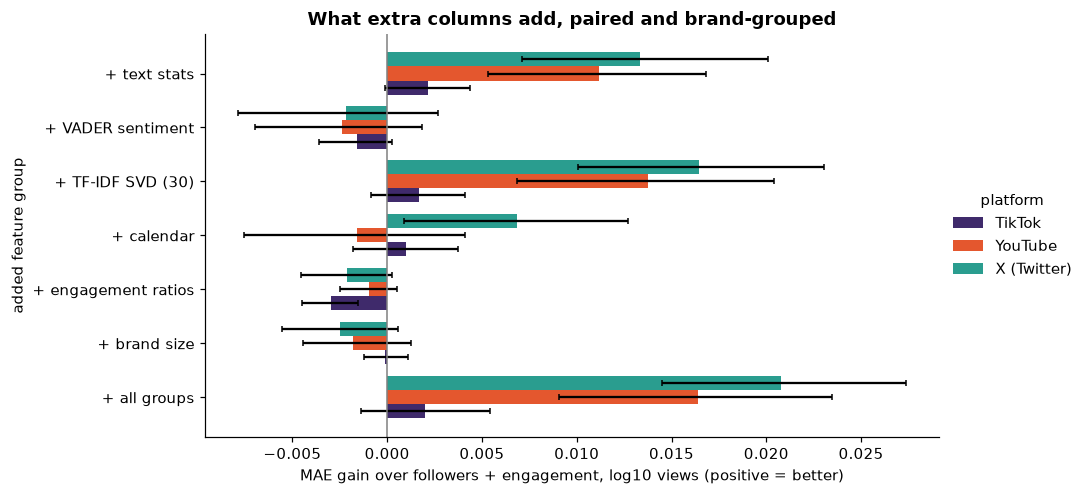

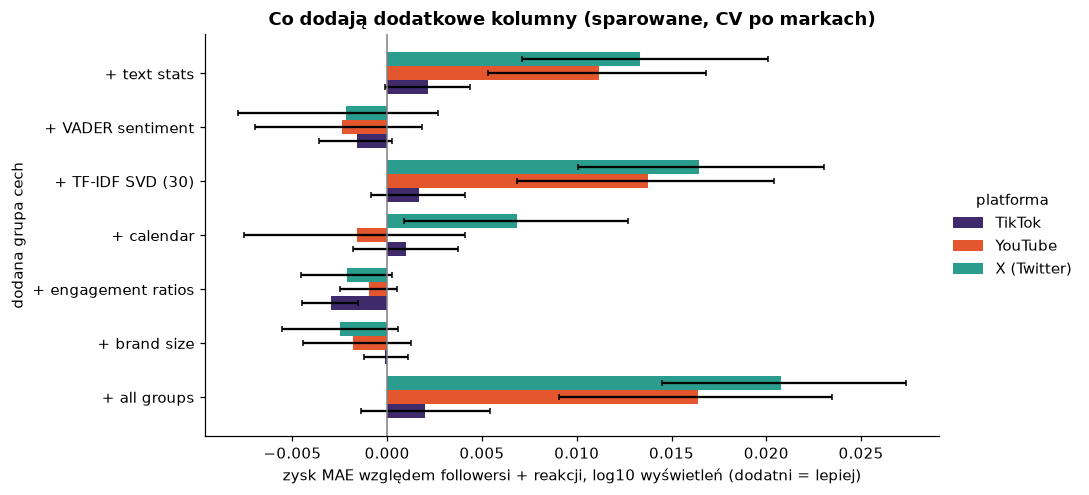

In [5]:
ni.plot_gains(lad, ROOT / 'figures' / 'gains_en.png', 'en'); ni.plot_gains(lad, ROOT / 'figures' / 'gains_pl.png', 'pl')

In [6]:
lad[lad.model != lad.model.iloc[0]][['platform', 'model', 'gain vs base', 'gain low', 'gain high']].round(3).reset_index(drop=True)

,platform,model,gain vs base,gain low,gain high
0,TikTok,+ text stats,0.002,-0.000,0.004
1,TikTok,+ VADER sentiment,-0.002,-0.004,0.000
2,TikTok,+ TF-IDF SVD (30),0.002,-0.001,0.004
3,TikTok,+ calendar,0.001,-0.002,0.004
4,TikTok,+ engagement ratios,-0.003,-0.005,-0.002
5,TikTok,+ brand size,-0.000,-0.001,0.001
6,TikTok,+ all groups,0.002,-0.001,0.005
7,YouTube,+ text stats,0.011,0.005,0.017
8,YouTube,+ VADER sentiment,-0.002,-0.007,0.002
9,YouTube,+ TF-IDF SVD (30),0.014,0.007,0.020


Takeaway: text (basic statistics and TF-IDF topics) gives a small but real gain on YouTube and X. VADER sentiment, engagement ratios and brand size add nothing. TikTok gains nothing from any group.

## 2 · Can likes, comments, shares and followers be predicted?
Target on log scale; features exclude the target itself, our labels and views. Extra trees, brand-grouped CV; the baseline is the training-fold median.

In [7]:
tg = [ni.predict_target(f, meta, raw, G, p, n) for p in mo.PLATS for n in ["likes", "comments", "shares", "followers"]]
tg = pd.DataFrame([t for t in tg if t]); tg.round(3)

,platform,target,n,median baseline MAE,model MAE,CI low,CI high,R2
0,TikTok,likes,2491,1.666,0.863,0.836,0.888,0.760
1,TikTok,comments,2491,1.084,0.638,0.616,0.657,0.679
2,TikTok,shares,2491,1.233,0.680,0.654,0.707,0.751
3,TikTok,followers,2439,0.965,0.864,0.836,0.895,0.218
4,YouTube,likes,2335,1.975,0.925,0.878,0.966,0.717
5,YouTube,comments,2226,1.285,0.600,0.565,0.631,0.734
6,YouTube,shares,1451,0.000,0.000,0.000,0.000,NaN
7,YouTube,followers,2428,0.886,0.654,0.621,0.689,0.435
8,X (Twitter),likes,1803,0.551,0.455,0.433,0.474,0.591
9,X (Twitter),comments,704,0.491,0.330,0.297,0.361,0.490


Takeaway: likes, comments and shares are predictable (R2 0.5 to 0.8) because they move together, and text adds some. **Followers are hard to predict** (R2 0.15 to 0.44), so followers carry information the post itself does not. YouTube shares are almost all zero and are skipped as a target.

## 3 · Brand graph
Each brand is a node; edges = cosine similarity of the TF-IDF of all its mentions (topic or industry). For a test brand, take its 5 nearest **training** brands and use their mean engagement-adjusted residual and mean log views as features. Nothing from the test brand's own views is used.

In [8]:
bg = pd.DataFrame([ni.brand_graph_gain(f, meta, raw, p) for p in mo.PLATS])
bg.round(3)

,platform,base MAE,with brand-graph MAE,gain,gain low,gain high
0,TikTok,0.277,0.278,-0.001,-0.003,0.001
1,YouTube,0.455,0.460,-0.005,-0.010,-0.000
2,X (Twitter),0.481,0.471,0.011,0.003,0.018


Takeaway: the brand graph helps only on X (about 0.011 log10, CI above zero) and not on TikTok or YouTube. Similar brands share a views level on X after controlling for engagement.

## 4 · Everything together on X

In [9]:
p = "twitter"; m = (meta.platform == p).values; M = meta[m].reset_index(drop=True); y, g = M.y, M.brand
base = f[m][em.ENG].reset_index(drop=True); allg = pd.concat([base] + [v[m].reset_index(drop=True) for v in G.values()], axis=1)
t = (raw.title.fillna("") + " " + raw.content.fillna(""))[m].values; S = ni.brand_similarity(M, t)
mk = em.models()["extra trees"]; pb = em.cv_predict(mk, base, y, g); pa = em.cv_predict(mk, allg, y, g, ni.brand_neighbour_extra(M, allg, y, S))
gain = ni.paired_diff(y.values, pb, pa, g.values)
pd.Series({"base MAE": np.abs(y - pb).mean(), "all groups + brand graph MAE": np.abs(y - pa).mean(), "paired gain": gain[0], "gain low": gain[1], "gain high": gain[2]}).round(3).to_frame("X (Twitter)")

,X (Twitter)
base MAE,0.481
all groups + brand graph MAE,0.458
paired gain,0.023
gain low,0.016
gain high,0.030


## 5 · Ablation
Start from the full model (followers, engagement, missing flags and every extra group except the ratios, which contain likes and followers and would leak a removed group back in) and remove one group at a time. A positive loss means the group is needed. Log-style axis because engagement is huge and the rest is tiny.

In [10]:
ab = pd.concat([ni.ablation(f, meta, G, p) for p in mo.PLATS], ignore_index=True)
ab.pivot(index='removed group', columns='platform', values='loss').reindex(ab['removed group'].unique()).round(3)

platform,TikTok,X (Twitter),YouTube
removed group,,,
followers,0.002,0.037,0.021
engagement,0.316,0.080,0.230
missing flags,0.000,-0.002,0.006
text stats,0.002,0.003,0.003
VADER sentiment,-0.000,-0.001,-0.002
TF-IDF SVD (30),0.001,0.009,0.009
calendar,0.000,-0.001,0.001
brand size,0.001,-0.001,0.001


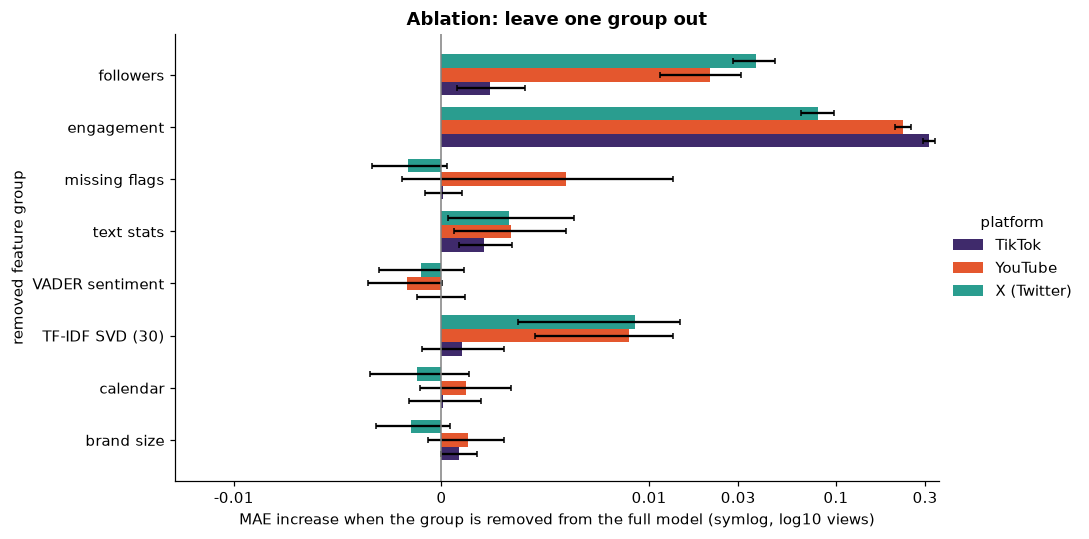

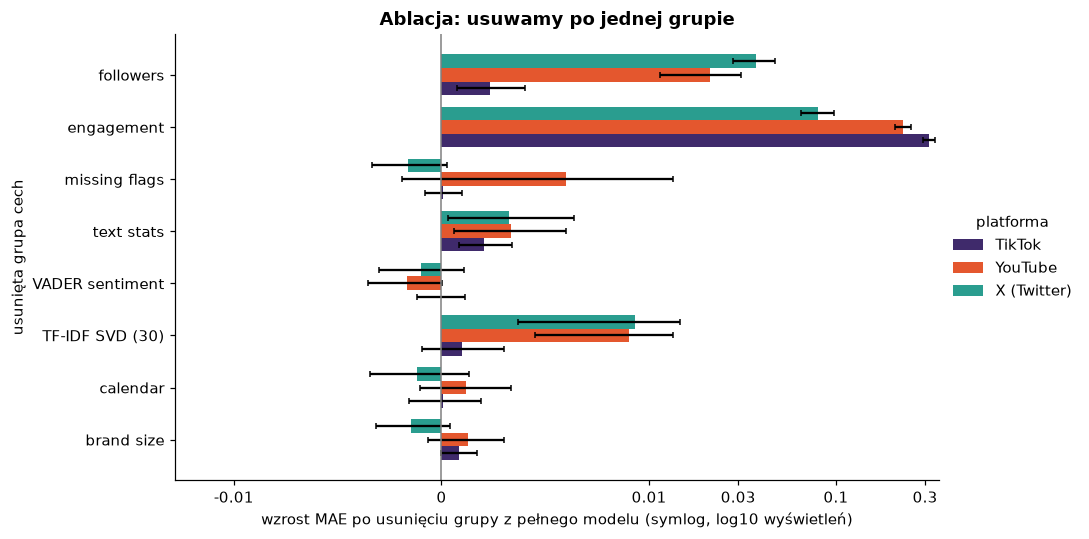

In [11]:
ni.plot_ablation(ab, ROOT / 'figures' / 'ablation_en.png', 'en'); ni.plot_ablation(ab, ROOT / 'figures' / 'ablation_pl.png', 'pl')

In [12]:
ab[['platform', 'removed group', 'loss', 'loss low', 'loss high']].round(3)

,platform,removed group,loss,loss low,loss high
0,TikTok,followers,0.002,0.001,0.004
1,TikTok,engagement,0.316,0.293,0.338
2,TikTok,missing flags,0.000,-0.001,0.001
3,TikTok,text stats,0.002,0.001,0.003
4,TikTok,VADER sentiment,-0.000,-0.001,0.001
5,TikTok,TF-IDF SVD (30),0.001,-0.001,0.003
6,TikTok,calendar,0.000,-0.002,0.002
7,TikTok,brand size,0.001,-0.000,0.002
8,YouTube,followers,0.021,0.011,0.031
9,YouTube,engagement,0.230,0.206,0.251


Takeaway: engagement is by far the most important group (removing it costs +0.32 on TikTok, +0.23 on YouTube, +0.08 on X where most posts lack likes). Followers matter on X and YouTube once text is in the model. Text statistics and TF-IDF topics cost a little when removed on YouTube and X. VADER, calendar, brand size and missing flags are not needed.

In [13]:
out = {"gains": lad.to_dict("records"), "targets": tg.to_dict("records"), "brand_graph": bg.to_dict("records"), "ablation": ab.to_dict("records"), "x_all": {"base": float(np.abs(y - pb).mean()), "all": float(np.abs(y - pa).mean()), "gain": gain[0], "low": gain[1], "high": gain[2]}}
json.dump(out, open(ROOT / "data" / "processed" / "extra_numbers.json", "w"), indent=1, default=float)